# MovieLens Exploratory Data Analysis (EDA) — Ratings, Sparsity & Thresholds

This notebook contains the end-to-end exploratory data analysis of **MovieLens 32M**: data loading, distribution analysis (ratings, users, movies), sparsity measurement, candidate threshold simulations, data checks (genres, titles, time range) and the final data pipeline recommendations.

> All the numbers in the insight cells are **computed when the notebook runs**, so they stay correct if the dataset changes.

## 1. Introduction & Setup

First, let's import the libraries we need for the EDA:
- **pandas** & **numpy**: data manipulation and basic numerical checks.
- **matplotlib** & **seaborn**: visualizations for the upcoming tasks.
- **pathlib**: cross-platform, relative paths so the notebook runs seamlessly on any teammate's machine.

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style for plots in upcoming tasks
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["font.size"] = 10

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
from IPython.display import Markdown, display


Libraries imported successfully!
Pandas version: 2.3.3


## 2. Data Loading

We resolve the project root dynamically using `pathlib.Path`, so there are no paths from anyone's computer.
The raw files of **MovieLens 32M** are in `data/raw/ml-32m/` (downloaded with `dvc pull`):
- `ratings.csv`: `userId, movieId, rating, timestamp` (0.5 to 5.0, half-star steps). ~32 million rows.
- `movies.csv`: `movieId, title, genres` (title with the year in parentheses, pipe-separated genres).
- `tags.csv`: free-text tags applied by users to movies.
- `links.csv`: identifiers to external databases (IMDb and TMDb).

> **Memory:** with ~32M ratings, the default pandas types take more than 1 GB. We load the ids as `int32`, the rating as `float32` and the timestamp as `int64`, which roughly halves the memory. If your computer runs out of memory, set `SAMPLE_USERS` to a number (for example `20_000`) to work with a random sample of users while you develop, and set it back to `None` for the final run.

In [22]:
import os
import time

SAMPLE_USERS = None         # e.g. 20_000 while developing; None = all users
RANDOM_STATE = 42

# Project-relative path resolution (with auto-recovery if kernel was active during git operations)
try:
    current_dir = Path.cwd()
except FileNotFoundError:
    candidate = Path.home() / 'Desktop' / 'master' / 'ADS' / 'ADS-B1' / 'team-B1-recsys' / 'notebooks'
    if not candidate.exists():
        candidate = Path.home() / 'Desktop' / 'master' / 'ADS' / 'ADS-B1' / 'team-B1-recsys'
    os.chdir(candidate)
    current_dir = candidate

repo_root = current_dir.parent if current_dir.name == 'notebooks' else current_dir

# Check if data is in data/raw/ml-32m or directly in data/raw/
if (repo_root / 'data' / 'raw' / 'ml-32m').exists() and (repo_root / 'data' / 'raw' / 'ml-32m' / 'ratings.csv').exists():
    raw_data_dir = repo_root / 'data' / 'raw' / 'ml-32m'
elif (repo_root / 'data' / 'raw' / 'ratings.csv').exists():
    raw_data_dir = repo_root / 'data' / 'raw'
else:
    raw_data_dir = repo_root / 'data' / 'raw' / 'ml-32m'
    raise FileNotFoundError(
        f"{raw_data_dir} not found. Download the data with `dvc pull` (see README) "
        f"or place MovieLens 32M CSVs into data/raw/ or data/raw/ml-32m/."
    )

print(f"Resolved repo root: {repo_root.resolve()}")
print(f"Raw data directory: {raw_data_dir.resolve()}")

t0 = time.time()
ratings = pd.read_csv(
    raw_data_dir / 'ratings.csv',
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'},
)
movies = pd.read_csv(raw_data_dir / 'movies.csv', dtype={'movieId': 'int32'})
tags = pd.read_csv(raw_data_dir / 'tags.csv', dtype={'userId': 'int32', 'movieId': 'int32'})
links = pd.read_csv(raw_data_dir / 'links.csv', dtype={'movieId': 'int32'})

if SAMPLE_USERS is not None:
    rng = np.random.default_rng(RANDOM_STATE)
    all_users = ratings['userId'].unique()
    keep = rng.choice(all_users, size=min(SAMPLE_USERS, len(all_users)), replace=False)
    ratings = ratings[ratings['userId'].isin(keep)].reset_index(drop=True)
    print(f"Working with a SAMPLE of {len(keep):,} users")

print(f"Loaded in {time.time() - t0:.1f} s")
print(f"ratings: {ratings.shape[0]:,} rows x {ratings.shape[1]} columns "
      f"({ratings.memory_usage(deep=True).sum() / 1e6:,.0f} MB)")
print(f"movies:  {movies.shape[0]:,} rows x {movies.shape[1]} columns")
print(f"tags:    {tags.shape[0]:,} rows x {tags.shape[1]} columns")
print(f"links:   {links.shape[0]:,} rows x {links.shape[1]} columns")


Resolved repo root: /Users/carla/Desktop/master/ADS/ADS-B1/team-B1-recsys
Raw data directory: /Users/carla/Desktop/master/ADS/ADS-B1/team-B1-recsys/data/raw
Loaded in 2.5 s
ratings: 32,000,204 rows x 4 columns (640 MB)
movies:  87,585 rows x 3 columns
tags:    2,000,072 rows x 4 columns
links:   87,585 rows x 3 columns


## 3. Initial Structure of the 4 Datasets

Let's check the schema, column types, and first few rows of each table.

### 3.1 Ratings table
This is our primary table for the recommender system. Each row represents a rating given by a `userId` to a `movieId` at a specific Unix `timestamp`.

In [23]:
print("Ratings Info:")
ratings.info()
ratings.head()

Ratings Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int32  
 1   movieId    int32  
 2   rating     float32
 3   timestamp  int64  
dtypes: float32(1), int32(2), int64(1)
memory usage: 610.4 MB


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


### 3.2 Movies table
Contains metadata about each movie: the unique `movieId`, the `title` (which includes the release year in parentheses), and pipe-separated `genres`.

In [24]:
print("Movies Info:")
movies.info()
movies.head()

Movies Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  87585 non-null  int32 
 1   title    87585 non-null  object
 2   genres   87585 non-null  object
dtypes: int32(1), object(2)
memory usage: 1.7+ MB


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


### 3.3 Tags table
Contains user-generated keyword tags. Useful to understand if tags can be leveraged for content-based features or cold-start recommendations.

In [25]:
print("Tags Info:")
tags.info()
tags.head()

Tags Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000072 entries, 0 to 2000071
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   userId     int32 
 1   movieId    int32 
 2   tag        object
 3   timestamp  int64 
dtypes: int32(2), int64(1), object(1)
memory usage: 45.8+ MB


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


### 3.4 Links table
Contains external identifiers (`imdbId`, `tmdbId`) linked to `movieId`. Useful if we later need to enrich movies with posters, synopses, or external metadata.

In [26]:
print("Links Info:")
links.info()
links.head()

Links Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  87585 non-null  int32  
 1   imdbId   87585 non-null  int64  
 2   tmdbId   87461 non-null  float64
dtypes: float64(1), int32(1), int64(1)
memory usage: 1.7 MB


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### 3.5 Quick Identifier Sanity Check
Let's verify the unique counts of primary keys (`userId`, `movieId`) across tables.

In [27]:
print(f"Unique users in ratings:  {ratings['userId'].nunique():,}")
print(f"Unique movies in ratings: {ratings['movieId'].nunique():,}")
print(f"Total movies in catalog:  {movies['movieId'].nunique():,}")
print(f"Unique users who tagged:  {tags['userId'].nunique():,}")
print(f"Unique tags applied:      {tags['tag'].str.lower().nunique():,}")

Unique users in ratings:  200,948
Unique movies in ratings: 84,432
Total movies in catalog:  87,585
Unique users who tagged:  15,848
Unique tags applied:      132,171


### 3.6 Time Range of the Ratings
The time range matters for the train/test split of the models (US2.2 uses a split by time).

First rating: 1995-01-09
Last rating:  2023-10-13


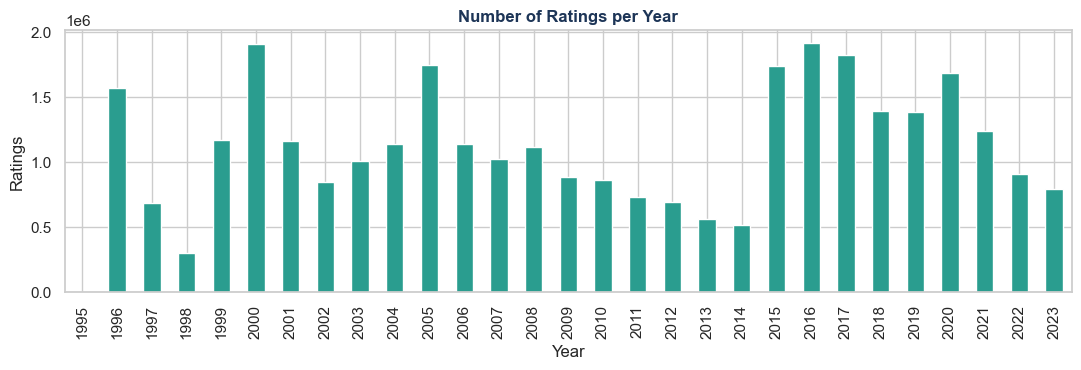

In [28]:
ts = pd.to_datetime(ratings['timestamp'], unit='s')
print(f"First rating: {ts.min():%Y-%m-%d}")
print(f"Last rating:  {ts.max():%Y-%m-%d}")
per_year = ts.dt.year.value_counts().sort_index()
plt.figure(figsize=(11, 3.8))
per_year.plot(kind='bar', color='#2a9d8f')
plt.title('Number of Ratings per Year', fontsize=12, fontweight='bold', color='#1d3557')
plt.xlabel('Year'); plt.ylabel('Ratings')
plt.tight_layout(); plt.show()


## 4. Distribution of Rating Values 

Let's explore how users assign rating scores on MovieLens (scale: 0.5 to 5.0, in half-star increments).
We want to answer:
- What is the most common rating value?
- Is there a positive or negative bias in user ratings?
- Do users tend to prefer integer ratings over half-star ratings?

=== Rating Values Summary ===
Total ratings: 32,000,204
Mean rating:   3.54
Median rating: 3.5
Std deviation: 1.09


,Rating,Count,Percentage (%)
0,0.5,525132,1.64
1,1.0,946675,2.96
2,1.5,531063,1.66
3,2.0,2028622,6.34
4,2.5,1685386,5.27
5,3.0,6054990,18.92
6,3.5,4290105,13.41
7,4.0,8367654,26.15
8,4.5,2974000,9.29
9,5.0,4596577,14.36


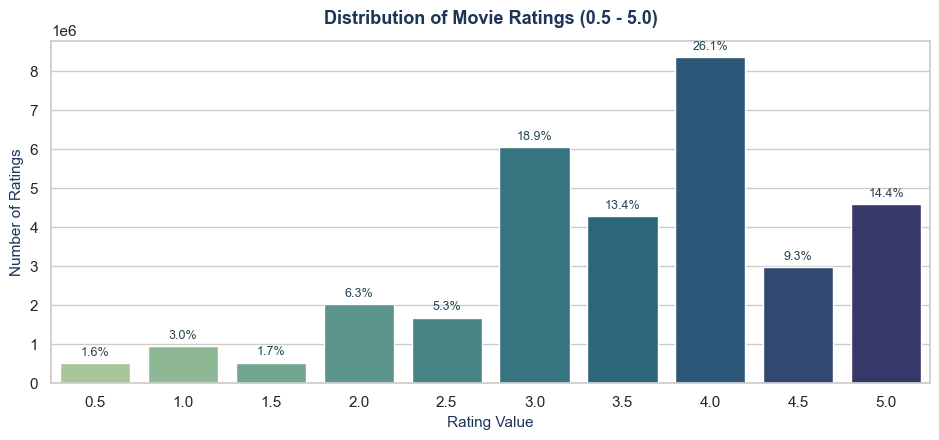

In [29]:
# Calculate frequency and percentage of each rating value
rating_counts = ratings['rating'].value_counts().sort_index()
rating_pcts = (ratings['rating'].value_counts(normalize=True).sort_index() * 100).round(2)

df_rating_dist = pd.DataFrame({
    'Rating': rating_counts.index,
    'Count': rating_counts.values,
    'Percentage (%)': rating_pcts.values
}).reset_index(drop=True)

print('=== Rating Values Summary ===')
print(f"Total ratings: {len(ratings):,}")
print(f"Mean rating:   {ratings['rating'].mean():.2f}")
print(f"Median rating: {ratings['rating'].median():.1f}")
print(f"Std deviation: {ratings['rating'].std():.2f}")
display(df_rating_dist)

# Plot distribution with aesthetic teal/blue gradient
plt.figure(figsize=(9.5, 4.5))
ax = sns.barplot(data=df_rating_dist, x='Rating', y='Count', hue='Rating', palette='crest', legend=False)
plt.title('Distribution of Movie Ratings (0.5 - 5.0)', fontsize=13, pad=12, fontweight='bold', color='#1d3557')
plt.xlabel('Rating Value', fontsize=11, color='#1d3557')
plt.ylabel('Number of Ratings', fontsize=11, color='#1d3557')

# Annotate bars with percentage
for p in ax.patches:
    height = p.get_height()
    pct = (height / len(ratings)) * 100
    ax.annotate(f"{pct:.1f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                textcoords='offset points', color='#264653', fontweight='medium')

plt.tight_layout()
plt.show()


In [30]:
share_3_plus = (ratings['rating'] >= 3.0).mean() * 100
top3 = df_rating_dist.sort_values('Count', ascending=False).head(3)
share_whole = ratings['rating'].isin([1.0, 2.0, 3.0, 4.0, 5.0]).mean() * 100
display(Markdown(f"""### Key Insights on Rating Values
1. **Positive bias:** the mean rating is **{ratings['rating'].mean():.2f}** and the median **{ratings['rating'].median():.1f}**. Ratings of 3.0 or higher are **{share_3_plus:.1f}%** of all ratings.
2. **Most frequent ratings:** {', '.join(f"**{r:.1f}** ({p:.1f}%)" for r, p in zip(top3['Rating'], top3['Percentage (%)']))}.
3. **Whole stars vs half stars:** whole-star ratings are **{share_whole:.1f}%** of all ratings (half stars were introduced later in MovieLens).
"""))


### Key Insights on Rating Values
1. **Positive bias:** the mean rating is **3.54** and the median **3.5**. Ratings of 3.0 or higher are **82.1%** of all ratings.
2. **Most frequent ratings:** **4.0** (26.1%), **3.0** (18.9%), **5.0** (14.4%).
3. **Whole stars vs half stars:** whole-star ratings are **68.7%** of all ratings (half stars were introduced later in MovieLens).


## 5. User Activity Distribution

Now let's examine how active individual users are. We want to know:
- How many ratings does each user provide?
- Are there inactive users or extreme 'superusers'?
- How is user activity distributed across the user base?

=== User Activity Summary ===
Total users:             200,948
Min ratings per user:    20
25th percentile (Q1):    36
Median (50th percentile):73
Mean ratings per user:   159.2
75th percentile (Q3):    167
95th percentile:         571
Max ratings per user:    33,332


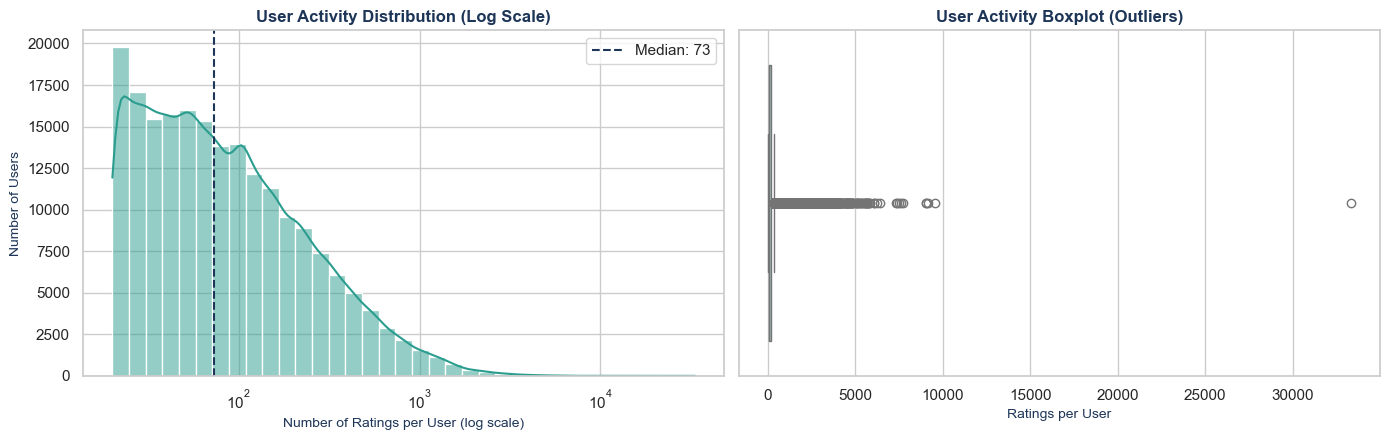

In [31]:
# Group ratings by userId
user_activity = ratings.groupby('userId').size()

print('=== User Activity Summary ===')
print(f"Total users:             {len(user_activity):,}")
print(f"Min ratings per user:    {user_activity.min():,}")
print(f"25th percentile (Q1):    {user_activity.quantile(0.25):.0f}")
print(f"Median (50th percentile):{user_activity.median():.0f}")
print(f"Mean ratings per user:   {user_activity.mean():.1f}")
print(f"75th percentile (Q3):    {user_activity.quantile(0.75):.0f}")
print(f"95th percentile:         {user_activity.quantile(0.95):.0f}")
print(f"Max ratings per user:    {user_activity.max():,}")

# Visualization: Long-tail distribution and Boxplot in teal and sea green
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Subplot 1: Distribution with log scale in sea green
sns.histplot(user_activity, bins=35, kde=True, color='#2a9d8f', ax=ax1, log_scale=True)
ax1.set_title('User Activity Distribution (Log Scale)', fontsize=12, fontweight='bold', color='#1d3557')
ax1.set_xlabel('Number of Ratings per User (log scale)', fontsize=10, color='#1d3557')
ax1.set_ylabel('Number of Users', fontsize=10, color='#1d3557')
ax1.axvline(user_activity.median(), color='#1d3557', linestyle='--', linewidth=1.5, label=f'Median: {user_activity.median():.0f}')
ax1.legend()

# Subplot 2: Boxplot in soft mint
sns.boxplot(x=user_activity, color='#a8dadc', ax=ax2)
ax2.set_title('User Activity Boxplot (Outliers)', fontsize=12, fontweight='bold', color='#1d3557')
ax2.set_xlabel('Ratings per User', fontsize=10, color='#1d3557')

plt.tight_layout()
plt.show()


In [32]:
users_sorted = user_activity.sort_values(ascending=False)
top10pct_n = max(1, int(len(users_sorted) * 0.10))
top10pct_share = users_sorted.head(top10pct_n).sum() / users_sorted.sum() * 100
top_user_share = users_sorted.iloc[0] / users_sorted.sum() * 100
display(Markdown(f"""### Key Insights on User Activity
1. **Minimum per user:** every user has at least **{user_activity.min():,} ratings**, so a minimum per user is already applied by MovieLens.
2. **Right-skewed (long tail):** the median user has **{user_activity.median():.0f}** ratings while the mean is **{user_activity.mean():.1f}**.
3. **Superusers:** the 95th percentile is **{user_activity.quantile(0.95):.0f}** ratings and the most active user has **{user_activity.max():,}** ({top_user_share:.2f}% of the dataset). The top 10% of users ({top10pct_n:,} users) give **{top10pct_share:.1f}%** of all ratings.
"""))


### Key Insights on User Activity
1. **Minimum per user:** every user has at least **20 ratings**, so a minimum per user is already applied by MovieLens.
2. **Right-skewed (long tail):** the median user has **73** ratings while the mean is **159.2**.
3. **Superusers:** the 95th percentile is **571** ratings and the most active user has **33,332** (0.10% of the dataset). The top 10% of users (20,094 users) give **47.2%** of all ratings.


## 6. Movie Popularity Distribution

Next, we look at the other side of the interaction matrix: movies.
We want to evaluate:
- How many ratings does each movie receive?
- What proportion of movies has very few ratings (e.g. 1 to 5)?
- Which are the most rated movies in the dataset?

=== Movie Popularity Summary ===
Total rated movies:             84,432 (out of 87,585 in catalog)
Min ratings per movie:          1
Median ratings:                 5
Mean ratings per movie:         379.0
Max ratings per movie:          102,929
Movies with exactly 1 rating:   18,607 (22.0%)
Movies with <= 5 ratings:       44,027 (52.1%)
Movies with <= 10 ratings:      53,911 (63.9%)

=== Top 10 Most Rated Movies ===


,title,rating_count,mean_rating,genres
0,"Shawshank Redemption, The (1994)",102929,4.404614,Crime|Drama
1,Forrest Gump (1994),100296,4.052744,Comedy|Drama|Romance|War
2,Pulp Fiction (1994),98409,4.196969,Comedy|Crime|Drama|Thriller
3,"Matrix, The (1999)",93808,4.156436,Action|Sci-Fi|Thriller
4,"Silence of the Lambs, The (1991)",90330,4.148367,Crime|Horror|Thriller
5,Star Wars: Episode IV - A New Hope (1977),85010,4.099823,Action|Adventure|Sci-Fi
6,Fight Club (1999),77332,4.228780,Action|Crime|Drama|Thriller
7,Jurassic Park (1993),75233,3.698623,Action|Adventure|Sci-Fi|Thriller
8,Schindler's List (1993),73849,4.236990,Drama|War
9,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.092134,Adventure|Fantasy


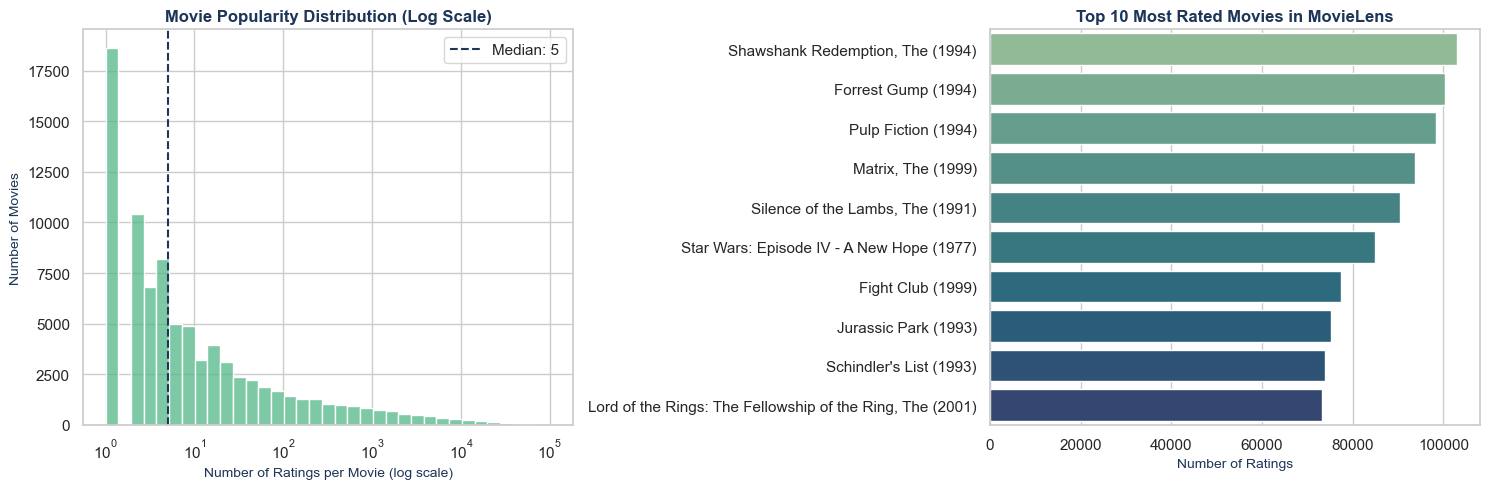

In [33]:
# Group ratings by movieId
movie_activity = ratings.groupby('movieId').size()

# Count low-frequency movies
movies_1 = (movie_activity == 1).sum()
movies_le5 = (movie_activity <= 5).sum()
movies_le10 = (movie_activity <= 10).sum()
n_rated_movies = len(movie_activity)

print('=== Movie Popularity Summary ===')
print(f"Total rated movies:             {n_rated_movies:,} (out of {len(movies):,} in catalog)")
print(f"Min ratings per movie:          {movie_activity.min():,}")
print(f"Median ratings:                 {movie_activity.median():.0f}")
print(f"Mean ratings per movie:         {movie_activity.mean():.1f}")
print(f"Max ratings per movie:          {movie_activity.max():,}")
print(f"Movies with exactly 1 rating:   {movies_1:,} ({movies_1 / n_rated_movies:.1%})")
print(f"Movies with <= 5 ratings:       {movies_le5:,} ({movies_le5 / n_rated_movies:.1%})")
print(f"Movies with <= 10 ratings:      {movies_le10:,} ({movies_le10 / n_rated_movies:.1%})")

# Top 10 most rated movies
top10_movies = (
    ratings.groupby('movieId')
    .agg(rating_count=('rating', 'count'), mean_rating=('rating', 'mean'))
    .reset_index()
    .merge(movies[['movieId', 'title', 'genres']], on='movieId')
    .sort_values(by='rating_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print('\n=== Top 10 Most Rated Movies ===')
display(top10_movies[['title', 'rating_count', 'mean_rating', 'genres']])

# Visualizations in fresh emerald green and blue-green
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Movie rating count distribution (log scale) in emerald green
sns.histplot(movie_activity, bins=35, color='#52b788', ax=ax1, log_scale=True)
ax1.set_title('Movie Popularity Distribution (Log Scale)', fontsize=12, fontweight='bold', color='#1d3557')
ax1.set_xlabel('Number of Ratings per Movie (log scale)', fontsize=10, color='#1d3557')
ax1.set_ylabel('Number of Movies', fontsize=10, color='#1d3557')
ax1.axvline(movie_activity.median(), color='#1d3557', linestyle='--', linewidth=1.5, label=f'Median: {movie_activity.median():.0f}')
ax1.legend()

# Subplot 2: Top 10 most rated movies in crest palette
sns.barplot(data=top10_movies, x='rating_count', y='title', hue='title', palette='crest', legend=False, ax=ax2)
ax2.set_title('Top 10 Most Rated Movies in MovieLens', fontsize=12, fontweight='bold', color='#1d3557')
ax2.set_xlabel('Number of Ratings', fontsize=10, color='#1d3557')
ax2.set_ylabel('')

plt.tight_layout()
plt.show()


In [34]:
display(Markdown(f"""### Key Insights on Movie Popularity
1. **Long tail:**
   - **{movies_1:,} movies ({movies_1 / n_rated_movies:.1%})** have **only 1 rating**.
   - **{movies_le5:,} movies ({movies_le5 / n_rated_movies:.1%})** have **5 or fewer**.
   - **{movies_le10:,} movies ({movies_le10 / n_rated_movies:.1%})** have **10 or fewer**.
2. **Noise problem:** movies with 1 or 2 ratings give almost no collaborative signal. A single 5.0 gives an average of 5.0, which would wrongly rank it above well-known classics.
3. **Not every movie in the catalogue is rated:** {len(movies) - n_rated_movies:,} of the {len(movies):,} movies have no ratings.
4. **Blockbusters:** the most rated movie, *{top10_movies.loc[0, 'title']}*, has **{top10_movies.loc[0, 'rating_count']:,}** ratings.
"""))


### Key Insights on Movie Popularity
1. **Long tail:**
   - **18,607 movies (22.0%)** have **only 1 rating**.
   - **44,027 movies (52.1%)** have **5 or fewer**.
   - **53,911 movies (63.9%)** have **10 or fewer**.
2. **Noise problem:** movies with 1 or 2 ratings give almost no collaborative signal. A single 5.0 gives an average of 5.0, which would wrongly rank it above well-known classics.
3. **Not every movie in the catalogue is rated:** 3,153 of the 87,585 movies have no ratings.
4. **Blockbusters:** the most rated movie, *Shawshank Redemption, The (1994)*, has **102,929** ratings.


## 7. User-Item Interaction Matrix Sparsity

In collaborative filtering, the data can be represented as a matrix $R$ of dimensions $|U| \times |I|$ where:
- $|U|$ is the number of users.
- $|I|$ is the number of items (movies), counted either as rated movies or as the full catalogue.
- Each cell $(u, i)$ contains the rating if user $u$ rated movie $i$, or is empty otherwise.

The **Sparsity** measures the percentage of missing user-movie interactions:

$$\text{Sparsity} = 1 - \frac{\text{Observed Ratings}}{|U| \times |I|}$$

$$\text{Density} = 100\% - \text{Sparsity} = \frac{\text{Observed Ratings}}{|U| \times |I|} \times 100$$

In [35]:
n_users = ratings['userId'].nunique()
n_movies_rated = ratings['movieId'].nunique()
n_movies_catalog = movies['movieId'].nunique()
n_ratings = len(ratings)

total_possible_rated = n_users * n_movies_rated
sparsity_rated = 1.0 - (n_ratings / total_possible_rated)
density_rated = (n_ratings / total_possible_rated) * 100

total_possible_catalog = n_users * n_movies_catalog
sparsity_catalog = 1.0 - (n_ratings / total_possible_catalog)
density_catalog = (n_ratings / total_possible_catalog) * 100

df_sparsity = pd.DataFrame({
    'Metric': [
        'Number of Users (|U|)',
        'Number of Movies (|I|)',
        'Total Possible Pairs (|U| x |I|)',
        'Observed Ratings',
        'Matrix Density (%)',
        'Matrix Sparsity (%)'
    ],
    f'Rated Movies ({n_movies_rated:,})': [
        f"{n_users:,}",
        f"{n_movies_rated:,}",
        f"{total_possible_rated:,}",
        f"{n_ratings:,}",
        f"{density_rated:.2f}%",
        f"{sparsity_rated * 100:.2f}%"
    ],
    f'Full Catalog ({n_movies_catalog:,})': [
        f"{n_users:,}",
        f"{n_movies_catalog:,}",
        f"{total_possible_catalog:,}",
        f"{n_ratings:,}",
        f"{density_catalog:.2f}%",
        f"{sparsity_catalog * 100:.2f}%"
    ]
})

print('=== User-Item Matrix Sparsity (AC3) ===')
display(df_sparsity)

=== User-Item Matrix Sparsity (AC3) ===


,Metric,"Rated Movies (84,432)","Full Catalog (87,585)"
0,Number of Users (|U|),"200,948","200,948"
1,Number of Movies (|I|),"84,432","87,585"
2,Total Possible Pairs (|U| x |I|),"16,966,441,536","17,600,030,580"
3,Observed Ratings,"32,000,204","32,000,204"
4,Matrix Density (%),0.19%,0.18%
5,Matrix Sparsity (%),99.81%,99.82%


In [36]:
display(Markdown(f"### Key Insights on Sparsity\n**Extreme sparsity ({sparsity_rated * 100:.2f}%)**: of the {total_possible_rated:,} possible user-movie pairs, only **{density_rated:.3f}%** have a rating."))


### Key Insights on Sparsity
**Extreme sparsity (99.81%)**: of the 16,966,441,536 possible user-movie pairs, only **0.189%** have a rating.

## 8. Candidate Thresholds Simulation & Data Loss Analysis

To choose an optimal cleaning threshold, we must quantify the trade-off between:
1. **Information Quality / Density**: Removing noisy movies with barely any ratings to reduce matrix sparsity.
2. **Data Retention**: Preserving as many ratings and active users as possible to avoid losing valuable interaction signal.

We simulate candidate thresholds of minimum ratings per movie: $k \in [1, 5, 10, 20, 50, 100]$.

=== Candidate Thresholds Simulation Results ===


,Min Ratings (k),Movies Kept,Movies Kept (%),Movies Lost (%),Ratings Kept,Ratings Kept (%),Data Loss (%),Users Kept (%),Density (%),Sparsity (%)
0,1,84432,100.0,0.0,32000204,100.0,0.0,100.0,0.19,99.81
1,5,43884,52.0,48.0,31921467,99.8,0.2,100.0,0.36,99.64
2,10,31961,37.9,62.1,31842705,99.5,0.5,100.0,0.50,99.50
3,20,23350,27.7,72.3,31725920,99.1,0.9,100.0,0.68,99.32
4,50,16034,19.0,81.0,31498689,98.4,1.6,100.0,0.98,99.02
5,100,12191,14.4,85.6,31228923,97.6,2.4,100.0,1.27,98.73


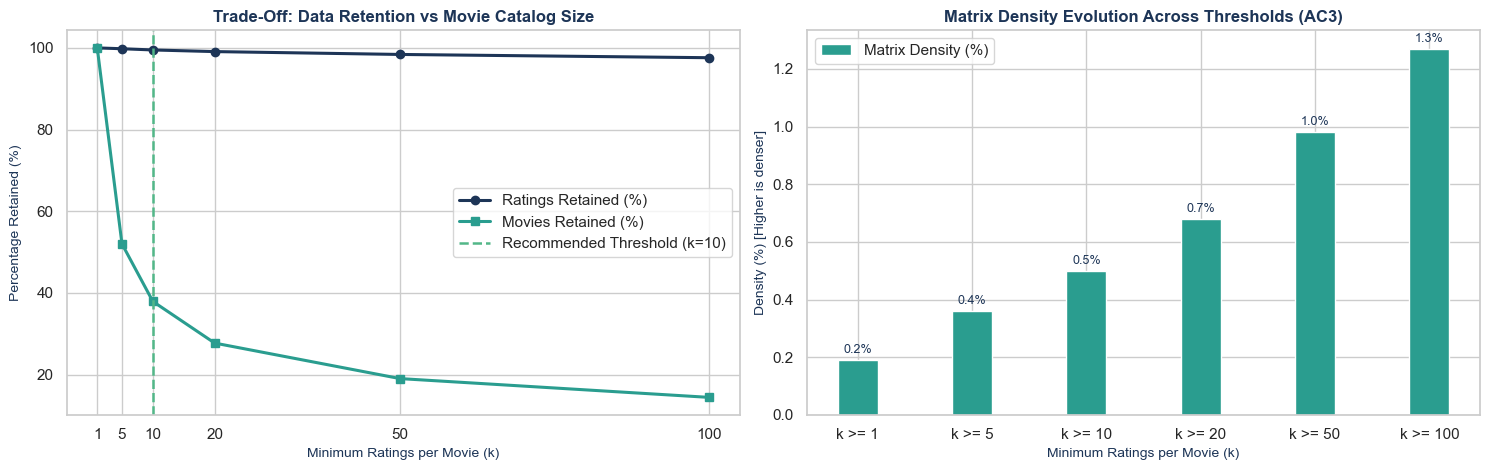

In [37]:
thresholds = [1, 5, 10, 20, 50, 100]
RECOMMENDED_K = 10  # re-check with the table below
sim_results = []
total_ratings = len(ratings)
total_movies = ratings['movieId'].nunique()
total_users = ratings['userId'].nunique()

movie_counts = ratings.groupby('movieId').size()

for k in thresholds:
    qual_movies = movie_counts[movie_counts >= k].index
    filt_df = ratings[ratings['movieId'].isin(qual_movies)]
    
    n_ratings_k = len(filt_df)
    n_movies_k = len(qual_movies)
    n_users_k = filt_df['userId'].nunique()
    
    pct_ratings_kept = (n_ratings_k / total_ratings) * 100
    pct_ratings_lost = 100.0 - pct_ratings_kept
    pct_movies_kept = (n_movies_k / total_movies) * 100
    pct_movies_lost = 100.0 - pct_movies_kept
    
    total_cells = n_users_k * n_movies_k
    density = (n_ratings_k / total_cells) * 100 if total_cells > 0 else 0
    sparsity = 100.0 - density
    
    sim_results.append({
        'Min Ratings (k)': k,
        'Movies Kept': n_movies_k,
        'Movies Kept (%)': round(pct_movies_kept, 1),
        'Movies Lost (%)': round(pct_movies_lost, 1),
        'Ratings Kept': n_ratings_k,
        'Ratings Kept (%)': round(pct_ratings_kept, 1),
        'Data Loss (%)': round(pct_ratings_lost, 1),
        'Users Kept (%)': round((n_users_k / total_users) * 100, 1),
        'Density (%)': round(density, 2),
        'Sparsity (%)': round(sparsity, 2)
    })

df_sim = pd.DataFrame(sim_results)
print('=== Candidate Thresholds Simulation Results ===')
display(df_sim)

# Visualizations in aesthetic blue and green tones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))

# Plot 1: Trade-off curves (Data Retention vs Movies Retained)
ax1.plot(df_sim['Min Ratings (k)'], df_sim['Ratings Kept (%)'], marker='o', color='#1d3557', linewidth=2.2, label='Ratings Retained (%)')
ax1.plot(df_sim['Min Ratings (k)'], df_sim['Movies Kept (%)'], marker='s', color='#2a9d8f', linewidth=2.2, label='Movies Retained (%)')
ax1.axvline(x=RECOMMENDED_K, color='#52b788', linestyle='--', linewidth=1.8, label=f'Recommended Threshold (k={RECOMMENDED_K})')
ax1.set_title('Trade-Off: Data Retention vs Movie Catalog Size', fontsize=12, fontweight='bold', color='#1d3557')
ax1.set_xlabel('Minimum Ratings per Movie (k)', fontsize=10, color='#1d3557')
ax1.set_ylabel('Percentage Retained (%)', fontsize=10, color='#1d3557')
ax1.set_xticks(df_sim['Min Ratings (k)'])
ax1.legend(loc='best')

# Plot 2: Sparsity & Density Evolution (AC3)
x_pos = np.arange(len(df_sim))
width = 0.35
ax2.bar(x_pos, df_sim['Density (%)'], width, label='Matrix Density (%)', color='#2a9d8f')
ax2.set_title('Matrix Density Evolution Across Thresholds (AC3)', fontsize=12, fontweight='bold', color='#1d3557')
ax2.set_xlabel('Minimum Ratings per Movie (k)', fontsize=10, color='#1d3557')
ax2.set_ylabel('Density (%) [Higher is denser]', fontsize=10, color='#1d3557')
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f'k >= {k}' for k in df_sim['Min Ratings (k)']])

# Annotate density percentages on bars
for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f"{height:.1f}%",
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                 textcoords='offset points', color='#1d3557', fontweight='medium')

ax2.legend()
plt.tight_layout()
plt.show()


## 8.1 Data Checks for the Pipeline and the API

Quick checks that the cleaning pipeline (US1.3) will automate, plus the genre names that the API moods in `params.yaml` must use.

In [38]:
valid_steps = np.arange(0.5, 5.01, 0.5)
checks = pd.DataFrame({
    'Check': [
        'Missing values in ratings',
        'Missing values in movies',
        'Ratings outside 0.5-5 or not in half steps',
        'Repeated userId-movieId ratings',
        'movieId in ratings but not in movies.csv',
        'Movies with "(no genres listed)"',
        'Titles without a (year)',
    ],
    'Problems found': [
        int(ratings.isna().sum().sum()),
        int(movies.isna().sum().sum()),
        int((~ratings['rating'].isin(valid_steps)).sum()),
        int(ratings.duplicated(['userId', 'movieId']).sum()),
        int((~ratings['movieId'].isin(movies['movieId'])).sum()),
        int((movies['genres'] == '(no genres listed)').sum()),
        int((~movies['title'].str.contains(r'\(\d{4}\)\s*$', regex=True)).sum()),
    ],
})
display(checks)

genre_counts = movies['genres'].str.split('|').explode().value_counts()
print('Genres in the catalogue (use these exact names in params.yaml moods):')
display(genre_counts.rename('movies').to_frame())


,Check,Problems found
0,Missing values in ratings,0
1,Missing values in movies,0
2,Ratings outside 0.5-5 or not in half steps,0
3,Repeated userId-movieId ratings,0
4,movieId in ratings but not in movies.csv,0
5,"Movies with ""(no genres listed)""",7080
6,Titles without a (year),617


Genres in the catalogue (use these exact names in params.yaml moods):


,movies
genres,
Drama,34175
Comedy,23124
Thriller,11823
Romance,10369
Action,9668
Documentary,9363
Horror,8654
(no genres listed),7080
Crime,6976


In [41]:
rec = df_sim.set_index('Min Ratings (k)')
base = rec.loc[1]
r = rec.loc[RECOMMENDED_K]
alt = rec.loc[5]
display(Markdown(f"""## 9. Written Threshold Recommendations

Based on the simulation above (MovieLens 32M), these are the thresholds for the data cleaning pipeline (US1.3).

### 1. Collaborative Filtering & Matrix Factorization (SVD)
- **Recommended threshold:** minimum **{RECOMMENDED_K} ratings per movie** ($k = {RECOMMENDED_K}$).
- **Why:**
  - Removes **{r['Movies Lost (%)']:.1f}%** of the movies (the ones with almost no signal, including all movies with a single rating).
  - Keeps **{r['Ratings Kept (%)']:.1f}%** of the ratings (data loss **{r['Data Loss (%)']:.1f}%**).
  - Keeps **{r['Users Kept (%)']:.1f}%** of the users.
  - Density goes from **{base['Density (%)']:.3f}%** to **{r['Density (%)']:.3f}%**.
- **Conservative alternative ($k = 5$):** keeps **{alt['Ratings Kept (%)']:.1f}%** of the ratings ({alt['Data Loss (%)']:.1f}% loss).
- **No minimum per user is needed:** MovieLens already gives at least {user_activity.min()} ratings per user.

### 2. Popularity Baseline Recommendations
- **Recommended threshold:** minimum **50 ratings per movie** ($k = 50$), for a reliable Bayesian weighted average in `baseline.py`. With 32M ratings this still keeps **{rec.loc[50, 'Movies Kept']:,.0f}** movies.
"""))


## 9. Written Threshold Recommendations

Based on the simulation above (MovieLens 32M), these are the thresholds for the data cleaning pipeline (US1.3).

### 1. Collaborative Filtering & Matrix Factorization (SVD)
- **Recommended threshold:** minimum **10 ratings per movie** ($k = 10$).
- **Why:**
  - Removes **62.1%** of the movies (the ones with almost no signal, including all movies with a single rating).
  - Keeps **99.5%** of the ratings (data loss **0.5%**).
  - Keeps **100.0%** of the users.
  - Density goes from **0.190%** to **0.500%**.
- **Conservative alternative ($k = 5$):** keeps **99.8%** of the ratings (0.2% loss).
- **No minimum per user is needed:** MovieLens already gives at least 20 ratings per user.

### 2. Popularity Baseline Recommendations
- **Recommended threshold:** minimum **50 ratings per movie** ($k = 50$), for a reliable Bayesian weighted average in `baseline.py`. With 32M ratings this still keeps **16,034** movies.


In [40]:
display(Markdown(f"""## 10. Conclusions - Key Dataset Findings & Data Pipeline Recommendations

### 1. Superuser Concentration (Power-Law Effect)
- **Observation:** the most active user has **{user_activity.max():,}** ratings ({top_user_share:.2f}% of the dataset), and the top 10% of users give **{top10pct_share:.1f}%** of all ratings.
- **Recommendation for modeling & evaluation:** global metrics would mostly reflect the taste of superusers. The team should also compute **stratified metrics** (low-activity users vs superusers) to check that the recommender works for average users (US2.2).

### 2. Identifier Types
- **Observation:** with ~32M rows, memory matters. Ids are loaded as `int32` and ratings as `float32`.
- **Recommendation for cleaning:** keep the ids as `int32` (not strings, which would use much more memory) and rename the columns to `user_id` and `movie_id`, which is what the API and the baseline expect. Save the clean data as **Parquet**.

### 3. Multi-Genre Parsing (`genres`)
- **Observation:** genres are pipe-separated, there are **{len(genre_counts)}** different values and **{int((movies['genres'] == '(no genres listed)').sum()):,}** movies have no genre.
- **Recommendation:** split with `.str.split('|')` when a model or the app needs it. The moods in `params.yaml` must use the exact names of section 8.1 (for example `Children`, not `Children's` as in MovieLens 1M).

### 4. Release Year in `title`
- **Observation:** the year is part of the title, e.g. `Toy Story (1995)`; **{int(checks.loc[6, 'Problems found']):,}** titles have no year.
- **Recommendation:** if a feature is needed later, extract it with the regex `\\((\\d{{4}})\\)` into `release_year`. Not needed for the SVD in Sprint 2.
"""))


## 10. Conclusions - Key Dataset Findings & Data Pipeline Recommendations

### 1. Superuser Concentration (Power-Law Effect)
- **Observation:** the most active user has **33,332** ratings (0.10% of the dataset), and the top 10% of users give **47.2%** of all ratings.
- **Recommendation for modeling & evaluation:** global metrics would mostly reflect the taste of superusers. The team should also compute **stratified metrics** (low-activity users vs superusers) to check that the recommender works for average users (US2.2).

### 2. Identifier Types
- **Observation:** with ~32M rows, memory matters. Ids are loaded as `int32` and ratings as `float32`.
- **Recommendation for cleaning:** keep the ids as `int32` (not strings, which would use much more memory) and rename the columns to `user_id` and `movie_id`, which is what the API and the baseline expect. Save the clean data as **Parquet**.

### 3. Multi-Genre Parsing (`genres`)
- **Observation:** genres are pipe-separated, there are **20** different values and **7,080** movies have no genre.
- **Recommendation:** split with `.str.split('|')` when a model or the app needs it. The moods in `params.yaml` must use the exact names of section 8.1 (for example `Children`, not `Children's` as in MovieLens 1M).

### 4. Release Year in `title`
- **Observation:** the year is part of the title, e.g. `Toy Story (1995)`; **617** titles have no year.
- **Recommendation:** if a feature is needed later, extract it with the regex `\((\d{4})\)` into `release_year`. Not needed for the SVD in Sprint 2.
